# Historical Average Delay Analysis

This notebook computes historical average delays per airport by weekday.

**Purpose**: Calculate average delays for operational analysis and feature engineering
**Input**: Historical flights data with scheduled and actual times
**Output**: Average delay tables by airport and weekday
**Scope**: Non-cancelled flights only, simple delay averages without thresholds

In [8]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

print("Libraries imported successfully")
print(f"Current time: {pd.Timestamp.now().strftime('%Y-%m-%d %H:%M:%S')}")

# Set up paths
data_path = Path('../data')
output_path = Path('../data')

# Configuration - Simple average delays only
MIN_FLIGHTS_FOR_AVERAGE = 10  # Minimum flights per weekday to calculate reliable average

# Plotting configuration  
plt.style.use('default')
sns.set_palette("husl")
plt.rcParams['figure.figsize'] = (12, 8)

Libraries imported successfully
Current time: 2025-09-23 16:01:11


## Load Historical Flight Data

In [9]:
# Load historical flights data
print("LOADING HISTORICAL FLIGHT DATA")
print("=" * 50)

flights_file = data_path / 'historical_flights.csv'
if not flights_file.exists():
    raise FileNotFoundError(f"Historical flights file not found: {flights_file}")

df_flights = pd.read_csv(flights_file)

print(f"Loaded {len(df_flights):,} flight records")
print(f"Date range: {df_flights['std'].min()} to {df_flights['std'].max()}")
print(f"Unique airports: {df_flights['dep_airport'].nunique()} departure, {df_flights['arr_airport'].nunique()} arrival")

# Display sample
print(f"\nSample flight data:")
print(df_flights[['flight_id', 'dep_airport', 'arr_airport', 'std', 'atd', 'sta', 'ata']].head())

LOADING HISTORICAL FLIGHT DATA
Loaded 410,442 flight records
Date range: 2018-01-01T07:20:00.000000 to 2025-07-31T21:40:00.000000
Unique airports: 118 departure, 122 arrival

Sample flight data:
  flight_id dep_airport arr_airport                         std  atd  \
0     WF149         HOV         OSL  2018-01-02T16:40:00.000000  NaN   
1     WF722         OSL         MJF  2018-01-28T13:04:00.000000  NaN   
2     WF188         FDE         OSL  2018-04-07T07:10:00.000000  NaN   
3     WF176         HOV         OSL  2018-04-07T11:00:00.000000  NaN   
4     WF148         HOV         OSL  2018-04-30T08:25:00.000000  NaN   

                          sta                         ata  
0  2018-01-02T17:15:00.000000  2018-01-02T18:53:00.000000  
1  2018-01-28T14:50:00.000000                         NaN  
2  2018-04-07T08:10:00.000000  2018-04-07T07:55:00.000000  
3  2018-04-07T12:05:00.000000  2018-04-07T12:00:00.000000  
4  2018-04-30T09:26:00.000000  2018-04-30T09:36:00.000000  
Loaded 410,4

## Data Preprocessing and Delay Calculation

In [10]:
# Filter out cancelled flights and prepare data
print("PREPROCESSING FLIGHT DATA")
print("=" * 40)

# Remove cancelled flights
initial_count = len(df_flights)
df_flights = df_flights[df_flights['cancelled'] == 0].copy()
print(f"Removed {initial_count - len(df_flights):,} cancelled flights")
print(f"Working with {len(df_flights):,} non-cancelled flights")

# Convert datetime columns
df_flights['std_dt'] = pd.to_datetime(df_flights['std'], utc=True)
df_flights['atd_dt'] = pd.to_datetime(df_flights['atd'], utc=True)
df_flights['sta_dt'] = pd.to_datetime(df_flights['sta'], utc=True)
df_flights['ata_dt'] = pd.to_datetime(df_flights['ata'], utc=True)

# Calculate delays in minutes
df_flights['dep_delay_minutes'] = (df_flights['atd_dt'] - df_flights['std_dt']).dt.total_seconds() / 60
df_flights['arr_delay_minutes'] = (df_flights['ata_dt'] - df_flights['sta_dt']).dt.total_seconds() / 60

# Add temporal features
df_flights['dep_weekday'] = df_flights['std_dt'].dt.day_name()
df_flights['arr_weekday'] = df_flights['sta_dt'].dt.day_name()
df_flights['dep_dow'] = df_flights['std_dt'].dt.dayofweek  # 0=Monday, 6=Sunday
df_flights['arr_dow'] = df_flights['sta_dt'].dt.dayofweek

# Remove rows with missing delay data
before_filter = len(df_flights)
df_flights = df_flights.dropna(subset=['dep_delay_minutes', 'arr_delay_minutes'])
print(f"Removed {before_filter - len(df_flights):,} flights with missing delay data")
print(f"Final dataset: {len(df_flights):,} flights with complete delay information")

# Summary statistics
print(f"\nDELAY SUMMARY:")
print(f"Average departure delay: {df_flights['dep_delay_minutes'].mean():.1f} minutes")
print(f"Average arrival delay: {df_flights['arr_delay_minutes'].mean():.1f} minutes")
print(f"Departure delay std: {df_flights['dep_delay_minutes'].std():.1f} minutes")
print(f"Arrival delay std: {df_flights['arr_delay_minutes'].std():.1f} minutes")

PREPROCESSING FLIGHT DATA


Removed 11,016 cancelled flights
Working with 399,426 non-cancelled flights
Removed 8,570 flights with missing delay data
Final dataset: 390,856 flights with complete delay information

DELAY SUMMARY:
Average departure delay: 2.6 minutes
Average arrival delay: 1.2 minutes
Departure delay std: 30.1 minutes
Arrival delay std: 55.4 minutes
Removed 8,570 flights with missing delay data
Final dataset: 390,856 flights with complete delay information

DELAY SUMMARY:
Average departure delay: 2.6 minutes
Average arrival delay: 1.2 minutes
Departure delay std: 30.1 minutes
Arrival delay std: 55.4 minutes


## Calculate Average Delays by Airport and Week Number

In [11]:
# Add ISO week number columns for scheduled departure and arrival
print("ADDING WEEK NUMBER FEATURES")
print("=" * 40)

df_flights['dep_week'] = df_flights['std_dt'].dt.isocalendar().week
# For arrival, use scheduled arrival time
if 'sta_dt' in df_flights.columns:
    df_flights['arr_week'] = df_flights['sta_dt'].dt.isocalendar().week
else:
    df_flights['arr_week'] = np.nan

# Calculate average delays by airport and week number
def calculate_average_delays_by_week(df, airport_col, week_col, delay_col, min_flights=MIN_FLIGHTS_FOR_AVERAGE):
    """
    Calculate average delays by airport and ISO week number
    Returns DataFrame with columns:
    - airport: airport code
    - week: ISO week number (1-52)
    - flight_count: number of flights
    - avg_delay_minutes: average delay in minutes
    - delay_std: standard deviation of delay
    - sufficient_data: whether we have enough flights for reliable average
    """
    grouped = df.groupby([airport_col, week_col]).agg({
        delay_col: ['count', 'mean', 'std']
    }).round(2)
    grouped.columns = ['flight_count', 'avg_delay_minutes', 'delay_std']
    grouped = grouped.reset_index()
    grouped = grouped.rename(columns={airport_col: 'airport', week_col: 'week'})
    grouped['sufficient_data'] = (grouped['flight_count'] >= min_flights).astype(int)
    grouped['delay_std'] = grouped['delay_std'].fillna(0)
    return grouped[['airport', 'week', 'flight_count', 'avg_delay_minutes', 'delay_std', 'sufficient_data']]

print("CALCULATING AVERAGE DELAYS BY WEEK NUMBER")
print("=" * 50)

dep_delays_week = calculate_average_delays_by_week(
    df_flights, 'dep_airport', 'dep_week', 'dep_delay_minutes'
)

arr_delays_week = calculate_average_delays_by_week(
    df_flights, 'arr_airport', 'arr_week', 'arr_delay_minutes'
)

print(f"Departure delay averages: {len(dep_delays_week):,} airport-week combinations")
print(f"Arrival delay averages: {len(arr_delays_week):,} airport-week combinations")

if not dep_delays_week.empty:
    dep_airports = dep_delays_week['airport'].nunique()
    dep_sufficient = dep_delays_week['sufficient_data'].sum()
    print(f"Departure airports covered: {dep_airports}")
    print(f"Departure averages with sufficient data (>={MIN_FLIGHTS_FOR_AVERAGE} flights): {dep_sufficient:,}")

if not arr_delays_week.empty:
    arr_airports = arr_delays_week['airport'].nunique()
    arr_sufficient = arr_delays_week['sufficient_data'].sum()
    print(f"Arrival airports covered: {arr_airports}")
    print(f"Arrival averages with sufficient data (>={MIN_FLIGHTS_FOR_AVERAGE} flights): {arr_sufficient:,}")

# Show samples
print(f"\nSample departure delays by week:")
if not dep_delays_week.empty:
    sample_dep = dep_delays_week.head(10)
    print(sample_dep.to_string(index=False))

print(f"\nSample arrival delays by week:")
if not arr_delays_week.empty:
    sample_arr = arr_delays_week.head(10)
    print(sample_arr.to_string(index=False))

ADDING WEEK NUMBER FEATURES
CALCULATING AVERAGE DELAYS BY WEEK NUMBER
Departure delay averages: 2,107 airport-week combinations
Arrival delay averages: 2,013 airport-week combinations
Departure airports covered: 73
Departure averages with sufficient data (>=10 flights): 1,723
Arrival airports covered: 60
Arrival averages with sufficient data (>=10 flights): 1,720

Sample departure delays by week:
airport  week  flight_count  avg_delay_minutes  delay_std  sufficient_data
    AES     1             5              31.80      42.14                0
    AES     2             5              10.60       5.32                0
    AES     3             5              57.40      68.90                0
    AES     4             1              38.00       0.00                0
    AES     5             2              68.50      34.65                0
    AES     6             4              37.25      39.99                0
    AES     7             1              11.00       0.00                0


## Calculate Average Delays by Airport and Weekday

In [12]:
def calculate_average_delays_by_weekday(df, airport_col, weekday_col, delay_col, min_flights=MIN_FLIGHTS_FOR_AVERAGE):
    """
    Calculate average delays by airport and weekday
    
    Returns DataFrame with columns:
    - airport: airport code
    - weekday: day name (Monday, Tuesday, etc.)
    - dow: day of week number (0=Monday, 6=Sunday)
    - flight_count: number of flights
    - avg_delay_minutes: average delay in minutes
    - sufficient_data: whether we have enough flights for reliable average
    """
    # Group by airport and weekday
    grouped = df.groupby([airport_col, weekday_col, df[weekday_col.replace('weekday', 'dow')]]).agg({
        delay_col: ['count', 'mean', 'std']
    }).round(2)
    
    # Flatten column names
    grouped.columns = ['flight_count', 'avg_delay_minutes', 'delay_std']
    grouped = grouped.reset_index()
    
    # Rename columns for consistency
    grouped = grouped.rename(columns={
        airport_col: 'airport',
        weekday_col: 'weekday',
        weekday_col.replace('weekday', 'dow'): 'dow'
    })
    
    # Mark sufficient data
    grouped['sufficient_data'] = (grouped['flight_count'] >= min_flights).astype(int)
    
    # Fill NaN standard deviations with 0 (for cases with only 1 flight)
    grouped['delay_std'] = grouped['delay_std'].fillna(0)
    
    return grouped[['airport', 'weekday', 'dow', 'flight_count', 'avg_delay_minutes', 'delay_std', 'sufficient_data']]

print("CALCULATING AVERAGE DELAYS BY WEEKDAY")
print("=" * 50)

# Calculate departure delays by weekday
dep_delays_weekday = calculate_average_delays_by_weekday(
    df_flights, 'dep_airport', 'dep_weekday', 'dep_delay_minutes'
)

# Calculate arrival delays by weekday  
arr_delays_weekday = calculate_average_delays_by_weekday(
    df_flights, 'arr_airport', 'arr_weekday', 'arr_delay_minutes'
)

print(f"RESULTS:")
print(f"Departure delay averages: {len(dep_delays_weekday):,} airport-weekday combinations")
print(f"Arrival delay averages: {len(arr_delays_weekday):,} airport-weekday combinations")

if not dep_delays_weekday.empty:
    dep_airports = dep_delays_weekday['airport'].nunique()
    dep_sufficient = dep_delays_weekday['sufficient_data'].sum()
    print(f"Departure airports covered: {dep_airports}")
    print(f"Departure averages with sufficient data (>={MIN_FLIGHTS_FOR_AVERAGE} flights): {dep_sufficient:,}")

if not arr_delays_weekday.empty:
    arr_airports = arr_delays_weekday['airport'].nunique()
    arr_sufficient = arr_delays_weekday['sufficient_data'].sum()
    print(f"Arrival airports covered: {arr_airports}")
    print(f"Arrival averages with sufficient data (>={MIN_FLIGHTS_FOR_AVERAGE} flights): {arr_sufficient:,}")

# Show samples
print(f"\nSample departure delays by weekday:")
if not dep_delays_weekday.empty:
    sample_dep = dep_delays_weekday.head(10)
    print(sample_dep.to_string(index=False))

print(f"\nSample arrival delays by weekday:")
if not arr_delays_weekday.empty:
    sample_arr = arr_delays_weekday.head(10)
    print(sample_arr.to_string(index=False))

CALCULATING AVERAGE DELAYS BY WEEKDAY
RESULTS:
Departure delay averages: 330 airport-weekday combinations
Arrival delay averages: 311 airport-weekday combinations
Departure airports covered: 73
Departure averages with sufficient data (>=10 flights): 257
Arrival airports covered: 60
Arrival averages with sufficient data (>=10 flights): 247

Sample departure delays by weekday:
airport   weekday  dow  flight_count  avg_delay_minutes  delay_std  sufficient_data
    AES    Friday    4            12              19.67      42.66                1
    AES    Monday    0            13              33.54      51.93                1
    AES  Saturday    5            12              28.83      51.26                1
    AES    Sunday    6            10              31.90      37.96                1
    AES  Thursday    3            22               9.64      20.08                1
    AES   Tuesday    1            17              18.76      44.09                1
    AES Wednesday    2            

## Overall Delay Patterns Analysis

In [13]:
# Aggregate delay patterns across all airports by weekday
def aggregate_delays_by_weekday(delays_df):
    """Aggregate delays by weekday across all airports, weighted by flight count"""
    if delays_df.empty:
        return pd.DataFrame()
    
    # Weight by flight count to get accurate overall averages
    weekday_agg = delays_df.groupby(['weekday', 'dow']).apply(
        lambda x: pd.Series({
            'total_flights': x['flight_count'].sum(),
            'total_delay_minutes': (x['flight_count'] * x['avg_delay_minutes']).sum(),
            'airports': x['airport'].nunique()
        })
    ).reset_index()
    
    # Calculate weighted average delay
    weekday_agg['avg_delay_minutes'] = (
        weekday_agg['total_delay_minutes'] / weekday_agg['total_flights']
    ).round(2)
    
    # Sort by day of week
    weekday_agg = weekday_agg.sort_values('dow').reset_index(drop=True)
    
    return weekday_agg[['weekday', 'dow', 'total_flights', 'avg_delay_minutes', 'airports']]

print("OVERALL DELAY PATTERNS BY WEEKDAY")
print("=" * 40)

# Analyze departure patterns
if not dep_delays_weekday.empty:
    dep_weekly_pattern = aggregate_delays_by_weekday(dep_delays_weekday)
    print("DEPARTURE DELAY PATTERNS BY WEEKDAY:")
    print(dep_weekly_pattern.to_string(index=False))
    
    if not dep_weekly_pattern.empty:
        worst_dep_day = dep_weekly_pattern.loc[dep_weekly_pattern['avg_delay_minutes'].idxmax()]
        best_dep_day = dep_weekly_pattern.loc[dep_weekly_pattern['avg_delay_minutes'].idxmin()]
        print(f"\nWorst departure delays: {worst_dep_day['weekday']} ({worst_dep_day['avg_delay_minutes']:.1f} min avg)")
        print(f"Best departure delays: {best_dep_day['weekday']} ({best_dep_day['avg_delay_minutes']:.1f} min avg)")

# Analyze arrival patterns
if not arr_delays_weekday.empty:
    arr_weekly_pattern = aggregate_delays_by_weekday(arr_delays_weekday)
    print(f"\nARRIVAL DELAY PATTERNS BY WEEKDAY:")
    print(arr_weekly_pattern.to_string(index=False))
    
    if not arr_weekly_pattern.empty:
        worst_arr_day = arr_weekly_pattern.loc[arr_weekly_pattern['avg_delay_minutes'].idxmax()]
        best_arr_day = arr_weekly_pattern.loc[arr_weekly_pattern['avg_delay_minutes'].idxmin()]
        print(f"\nWorst arrival delays: {worst_arr_day['weekday']} ({worst_arr_day['avg_delay_minutes']:.1f} min avg)")
        print(f"Best arrival delays: {best_arr_day['weekday']} ({best_arr_day['avg_delay_minutes']:.1f} min avg)")

OVERALL DELAY PATTERNS BY WEEKDAY
DEPARTURE DELAY PATTERNS BY WEEKDAY:
  weekday  dow  total_flights  avg_delay_minutes  airports
   Monday    0        65898.0               2.95      44.0
  Tuesday    1        65716.0               0.86      49.0
Wednesday    2        66711.0               1.94      53.0
 Thursday    3        65217.0               2.44      49.0
   Friday    4        65353.0               3.96      47.0
 Saturday    5        16658.0               2.75      42.0
   Sunday    6        45303.0               4.01      46.0

Worst departure delays: Sunday (4.0 min avg)
Best departure delays: Tuesday (0.9 min avg)

ARRIVAL DELAY PATTERNS BY WEEKDAY:
  weekday  dow  total_flights  avg_delay_minutes  airports
   Monday    0        65910.0               1.78      43.0
  Tuesday    1        65710.0              -0.30      43.0
Wednesday    2        66711.0               0.13      47.0
 Thursday    3        65220.0               1.31      45.0
   Friday    4        65356.0      

## Save Delay Lookup Tables

In [14]:
# Save delay lookup tables for feature engineering
print("SAVING DELAY LOOKUP TABLES")
print("=" * 30)

# Save departure delays by weekday
dep_output_file = output_path / 'departure_delays_by_weekday.csv'
dep_delays_weekday.to_csv(dep_output_file, index=False)
print(f"Saved departure delays: {dep_output_file}")
print(f"  Shape: {dep_delays_weekday.shape}")

# Save arrival delays by weekday  
arr_output_file = output_path / 'arrival_delays_by_weekday.csv'
arr_delays_weekday.to_csv(arr_output_file, index=False)
print(f"Saved arrival delays: {arr_output_file}")
print(f"  Shape: {arr_delays_weekday.shape}")

# Save overall patterns
if not dep_delays_weekday.empty and 'dep_weekly_pattern' in locals():
    overall_dep_file = output_path / 'overall_departure_delays_by_weekday.csv'
    dep_weekly_pattern.to_csv(overall_dep_file, index=False)
    print(f"Saved overall departure patterns: {overall_dep_file}")

if not arr_delays_weekday.empty and 'arr_weekly_pattern' in locals():
    overall_arr_file = output_path / 'overall_arrival_delays_by_weekday.csv'
    arr_weekly_pattern.to_csv(overall_arr_file, index=False)
    print(f"Saved overall arrival patterns: {overall_arr_file}")

print("\nAll delay lookup tables saved successfully!")
print("These files can be used for fast delay feature engineering.")

SAVING DELAY LOOKUP TABLES
Saved departure delays: ..\data\departure_delays_by_weekday.csv
  Shape: (330, 7)
Saved arrival delays: ..\data\arrival_delays_by_weekday.csv
  Shape: (311, 7)
Saved overall departure patterns: ..\data\overall_departure_delays_by_weekday.csv
Saved overall arrival patterns: ..\data\overall_arrival_delays_by_weekday.csv

All delay lookup tables saved successfully!
These files can be used for fast delay feature engineering.


## Visualization of Delay Patterns

CREATING DELAY PATTERN VISUALIZATIONS


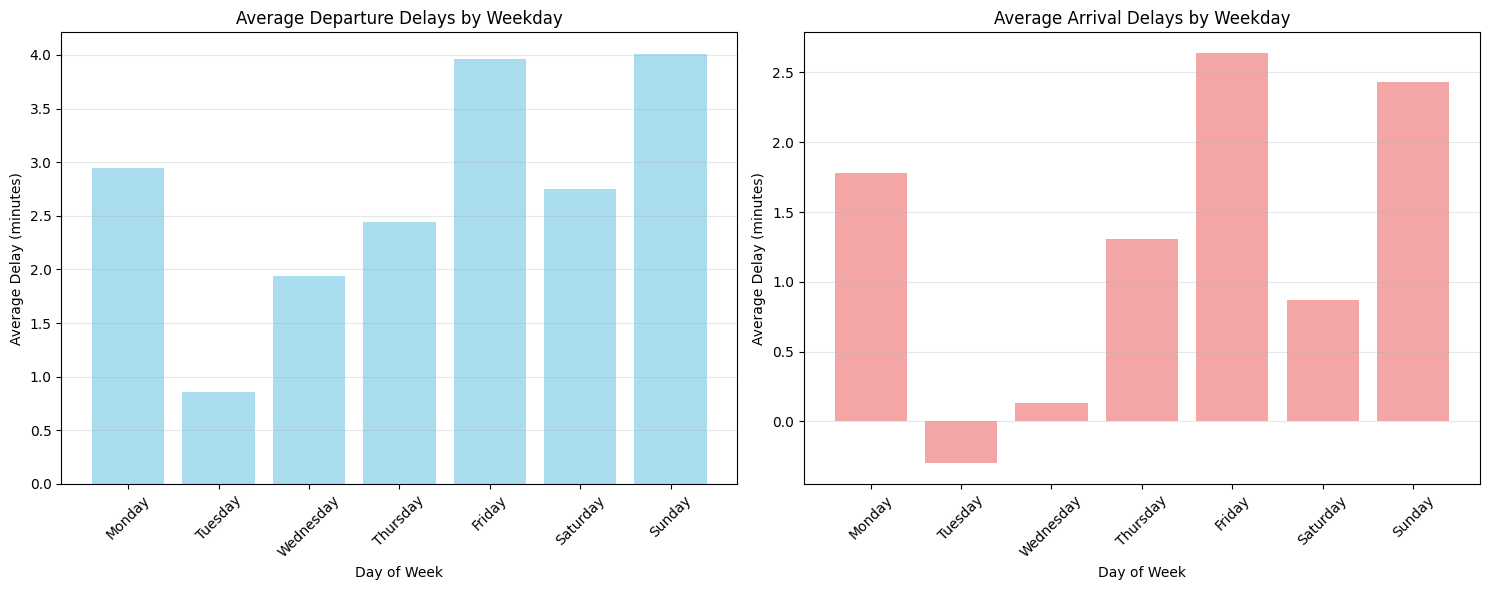


TOP 10 AIRPORTS WITH HIGHEST AVERAGE DEPARTURE DELAYS:
airport  flight_count  avg_delay_minutes
    LKL            52          27.580000
    LPA            77          27.040000
    AES           104          25.001429
    KSU           429          10.000000
    HAA          5339           8.725714
    TOS         11468           7.042857
    SSJ         11222           6.854286
    GDN            91           6.310000
    ANX           350           6.182857
    MQN         14678           5.254286

TOP 10 AIRPORTS WITH HIGHEST AVERAGE ARRIVAL DELAYS:
airport  flight_count  avg_delay_minutes
    AES            59          18.441429
    SSJ         11217           6.451429
    MJF         11686           5.511429
    SOJ          5303           5.085714
    HAA          5299           4.567143
    GDN            93           4.411667
    MQN         14594           4.197143
    ANX           350           3.562857
    RET          4297           3.554286
    MOL         17044        

In [ ]:
# Create visualizations of delay patterns
print("CREATING DELAY PATTERN VISUALIZATIONS")
print("=" * 40)

# Plot overall delay patterns by weekday
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Departure delays by weekday
if not dep_delays_weekday.empty and 'dep_weekly_pattern' in locals():
    ax1.bar(dep_weekly_pattern['weekday'], dep_weekly_pattern['avg_delay_minutes'], 
            color='skyblue', alpha=0.7)
    ax1.set_title('Average Departure Delays by Weekday')
    ax1.set_ylabel('Average Delay (minutes)')
    ax1.set_xlabel('Day of Week')
    ax1.tick_params(axis='x', rotation=45)
    ax1.grid(axis='y', alpha=0.3)

# Arrival delays by weekday
if not arr_delays_weekday.empty and 'arr_weekly_pattern' in locals():
    ax2.bar(arr_weekly_pattern['weekday'], arr_weekly_pattern['avg_delay_minutes'], 
            color='lightcoral', alpha=0.7)
    ax2.set_title('Average Arrival Delays by Weekday')
    ax2.set_ylabel('Average Delay (minutes)')
    ax2.set_xlabel('Day of Week')
    ax2.tick_params(axis='x', rotation=45)
    ax2.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

# Show top airports with highest average delays
print("\nTOP 10 AIRPORTS WITH HIGHEST AVERAGE DEPARTURE DELAYS:")
if not dep_delays_weekday.empty:
    top_dep_airports = dep_delays_weekday.groupby('airport').agg({
        'flight_count': 'sum',
        'avg_delay_minutes': 'mean'
    }).reset_index()
    top_dep_airports = top_dep_airports[top_dep_airports['flight_count'] >= 50]  # Min 50 flights total
    top_dep_airports = top_dep_airports.sort_values('avg_delay_minutes', ascending=False).head(10)
    print(top_dep_airports.to_string(index=False))

print("\nTOP 10 AIRPORTS WITH HIGHEST AVERAGE ARRIVAL DELAYS:")
if not arr_delays_weekday.empty:
    top_arr_airports = arr_delays_weekday.groupby('airport').agg({
        'flight_count': 'sum', 
        'avg_delay_minutes': 'mean'
    }).reset_index()
    top_arr_airports = top_arr_airports[top_arr_airports['flight_count'] >= 50]  # Min 50 flights total
    top_arr_airports = top_arr_airports.sort_values('avg_delay_minutes', ascending=False).head(10)
    print(top_arr_airports.to_string(index=False))